# GAN lab: from random digits to requested digits

**Student notebook · approximately three hours plus training time**

Complete the `TODO` functions, run the checks, and investigate how adversarial training behaves. The architectures, data handling, and plotting are supplied. Prerequisites: PyTorch modules, autograd, binary cross-entropy, and the GAN lectures.

By the end you should be able to implement alternating updates, explain gradient flow, compare a controlled intervention, and condition generation on digit identity.

| Part | Work | Suggested active time |
|---|---|---|
| A | Complete and check the training steps | 40 min |
| B | Train a vanilla GAN and inspect samples | 25 min |
| C | Change only the discriminator learning rate | 35 min |
| D | Complete conditional inputs and inspect control/diversity | 50 min |
| E | Interpret and submit results | 30 min |

Training time depends on hardware. Short runs are not guaranteed to produce recognizable digits. No pretrained weights or measured results are bundled.


## Setup: Kaggle or local Jupyter

- **Kaggle:** upload this notebook, enable a GPU accelerator, and enable internet for the initial MNIST download. For offline use, attach original MNIST IDX files (plain or gzip); CSV-only datasets are not supported.
- **Local:** open with a Python 3 Jupyter kernel containing `torch`, `torchvision`, and `matplotlib`. CPU works, but convolutional training can be slow. If needed, run the optional installation cell and restart the kernel.
- Output goes to `/kaggle/working/gan_lab_student` on Kaggle or `./gan_lab_student` locally (the solution uses its own folder). Repeating a run name overwrites that run's artifacts.
- First complete the TODOs and run with `SMOKE_TEST=True`. Then set it to `False` and rerun from the configuration cell. Smoke mode uses two batches and one epoch; it checks execution, not learning.
- Offline locally, put original IDX files under `DATA_DIR/MNIST/raw` or set `OFFLINE_MNIST_DIR` to their parent directory. Both training and test image/label files are recommended for torchvision compatibility.

Reference lectures: `module1/lectures/gans/gan_basics.md`, `dcgan-lecture-notes.md`, and `conditional_gan.md`. Paths describe the repository; this notebook is otherwise self-contained.


In [16]:
# Optional: uncomment only if dependencies are missing.
# %pip install torch torchvision matplotlib


In [17]:
from pathlib import Path
import gzip
import shutil
import json
import time
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt

SEED = 42
LATENT_DIM, NUM_CLASSES, IMG_SIZE = 100, 10, 32
IMG_DIM = 28 * 28
BATCH_SIZE = 128
LR = 2e-4
BASELINE_EPOCHS = 10
CONDITIONAL_EPOCHS = 10
SMOKE_TEST = False
# Optional smaller training subset for limited hardware; use the same value for all runs.
TRAIN_LIMIT = None
OFFLINE_MNIST_DIR = None  # Example: Path('/path/to/mnist-files')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORK_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
DATA_DIR = WORK_DIR / 'data'
OUTPUT_DIR = WORK_DIR / 'gan_lab_student'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
print('Device:', DEVICE, '| Smoke mode:', SMOKE_TEST)
print('Outputs:', OUTPUT_DIR.resolve())


Device: cuda | Smoke mode: False
Outputs: /home/akash/A Nitin/Akash/LAB-GENAI/generative_ai_shared/module1/labs/gans/gan_lab_student


## A. Alternating adversarial updates

Both discriminators in this lab return **logits**, with no final sigmoid. Use `BCEWithLogitsLoss` directly. This is equivalent in objective to the sigmoid + `BCELoss` formulation in the vanilla reference, with a numerically stable implementation.

For discriminator logits $s_r$ on real images and $s_f$ on generated images:

$$L_D=\operatorname{BCELogits}(s_r,1)+\operatorname{BCELogits}(s_f,0).$$

For the generator, recompute generated images and minimize:

$$L_G=\operatorname{BCELogits}(D(G(z)),1).$$

**TODO A1:** implement `discriminator_step`. Clear gradients, generate and detach fakes, compute both losses, backpropagate, and step only `opt_d`.

**TODO A2:** implement the marked generator block. Do not detach its fake images. The supplied wrapper freezes D's parameters and BatchNorm statistics while retaining autograd through D. Evaluation mode does not disable gradients.

`labels=None` means unconditional generation. Otherwise pass the class labels to both networks; these digit IDs are inputs, not BCE targets.


In [18]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim),
            nn.Tanh()          # output range [-1, 1]
        )

    def forward(self, z):
        return self.net(z)


# ----------------------------
# Discriminator: image -> real/fake logit
# ----------------------------
class VanillaDiscriminator(nn.Module):
    def __init__(self, img_dim=IMG_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x)


In [19]:
criterion = nn.BCEWithLogitsLoss()

def generate(g, z, labels=None):
    return g(z) if labels is None else g(z, labels)

def discriminate(d, images, labels=None):
    return d(images) if labels is None else d(images, labels)

def discriminator_step(g, d, opt_g, opt_d, real, labels=None):
    g.train()
    d.train()
    # TODO A1: implement the discriminator update described above.
    opt_d.zero_grad()
    batch_size = real.size(0)
    device = real.device
    d_real = discriminate(d, real, labels)
    loss_real = criterion(d_real, torch.ones_like(d_real))
    z = torch.randn(batch_size, LATENT_DIM, device=device)
    fake = generate(g, z, labels).detach()
    d_fake = discriminate(d, fake, labels)
    loss_fake = criterion(d_fake, torch.zeros_like(d_fake))
    loss_d = loss_real + loss_fake
    loss_d.backward()
    opt_d.step()
    return loss_d.item()

def generator_step(g, d, opt_g, opt_d, batch_size, labels=None):
    g.train()
    opt_g.zero_grad(set_to_none=True)
    opt_d.zero_grad(set_to_none=True)
    previous_mode = d.training
    d.requires_grad_(False)
    d.eval()
    try:
        # TODO A2: generate, score against ones, backpropagate, and update G.
        device = next(g.parameters()).device
        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake = generate(g, z, labels)
        d_fake = discriminate(d, fake, labels)
        loss_g = criterion(d_fake, torch.ones_like(d_fake))
        loss_g.backward()
        opt_g.step()
        return loss_g.item()
    finally:
        d.requires_grad_(True)
        d.train(previous_mode)


### Check gradient flow before downloading data

These checks use temporary networks and synthetic images. They verify that D's step leaves G's parameters and gradients alone, while G's step changes G without changing D's parameters or BatchNorm buffers. Passing does not establish generation quality.


In [20]:
def snapshot(module):
    return {k: v.detach().clone() for k, v in module.state_dict().items()}

def check_updates(g, d, real, labels=None):
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))
    before_g = {k: p.detach().clone() for k, p in g.named_parameters()}
    before_d = {k: p.detach().clone() for k, p in d.named_parameters()}
    dl = discriminator_step(g, d, opt_g, opt_d, real, labels)
    assert all(torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G updated in D step'
    assert all(p.grad is None for p in g.parameters()), 'Detach fakes in D step'
    assert any(not torch.equal(before_d[k], p) for k, p in d.named_parameters()), 'D did not update'
    d_state = snapshot(d)
    gl = generator_step(g, d, opt_g, opt_d, real.size(0), labels)
    assert any(not torch.equal(before_g[k], p) for k, p in g.named_parameters()), 'G did not update'
    assert all(torch.equal(d_state[k], v) for k, v in d.state_dict().items()), 'D changed in G step'
    assert all(p.grad is None for p in d.parameters()), 'D gradients should remain disabled'
    assert torch.isfinite(torch.tensor([dl, gl])).all()
    print('Update checks passed:', {'D': dl, 'G': gl})

seed_all(SEED)
check_updates(VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE),
              torch.rand(4, IMG_DIM, device=DEVICE) * 2 - 1)


Update checks passed: {'D': 1.3750903606414795, 'G': 0.682660698890686}


**Answer A:**
1. **Why G uses target 1 for fake images:** The generator minimizes $\operatorname{BCELogits}(D(G(z)), 1)$, which corresponds to the non-saturating objective $-\log D(G(z))$. Early in training when $D$ easily identifies fake images ($D(G(z)) \approx 0$), the original minimax objective $\log(1 - D(G(z)))$ has vanishing gradients. Using target 1 provides strong, non-vanishing gradient signals early on.
2. **Why `detach()` is only used in D's step:** During the discriminator update, we only want to optimize D's weights. Calling `fake.detach()` stops gradient flow back into G's computation graph, saving backward computation and memory, and ensuring G's weights remain unchanged during D's turn.
3. **What happens if `torch.no_grad()` surrounds D's forward pass during G's step:** `torch.no_grad()` disables tracking of the entire computation graph through $D$. Because the loss is calculated from D's output, gradients cannot backpropagate through $D$ to reach G's parameters ($z \to G \to D \to \text{loss}$). Consequently, G will receive no gradients and cannot learn. To prevent D from updating during G's step, one must freeze D's parameters (`requires_grad_(False)`), not disable gradient tracking.


## B. Load MNIST and train the baseline

Use 28 × 28 images for the supplied MLP and 32 × 32 for the conditional convolutional model. Normalize real pixels to [-1, 1] to match `Tanh`. The architectures differ in both resolution and capacity; do not interpret their comparison as an isolated test of conditioning.

Data order uses a separate seeded generator, so baseline and intervention see matching batches. A fixed random subset is used if `TRAIN_LIMIT` is set. Seeds improve repeatability but do not promise identical results across devices.


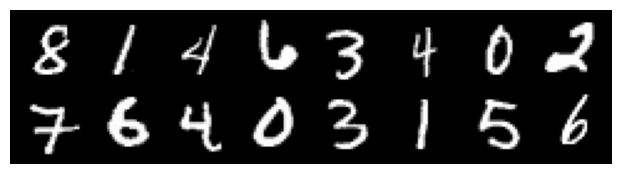

Training examples: 60000


In [21]:
raw_dir = DATA_DIR / "MNIST" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
input_dir = Path(OFFLINE_MNIST_DIR) if OFFLINE_MNIST_DIR is not None else Path("/kaggle/input")
raw_names = [
    "train-images-idx3-ubyte", "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte",
]
for name in raw_names:
    destination = raw_dir / name
    if destination.exists() or not input_dir.exists():
        continue
    aliases = [name, name.replace("-idx", ".idx")]
    candidates = sorted({path for alias in aliases
                         for pattern in (alias, alias + ".gz")
                         for path in input_dir.rglob(pattern) if path.is_file()})
    if candidates:
        source = candidates[0]
        opener = gzip.open if source.suffix == ".gz" else open
        with opener(source, "rb") as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)
        print("Loaded attached file:", source)

def load_mnist(size):
    transform = transforms.Compose([
        transforms.Resize(size), transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    try:
        return datasets.MNIST(str(DATA_DIR), train=True, download=False, transform=transform)
    except RuntimeError:
        try:
            return datasets.MNIST(str(DATA_DIR), train=True, download=True, transform=transform)
        except Exception as exc:
            raise RuntimeError('MNIST unavailable. Enable internet or supply original IDX files '
                               'using OFFLINE_MNIST_DIR (Kaggle: attach under /kaggle/input).') from exc

def make_loader(size):
    dataset = load_mnist(size)
    limit = 2 * BATCH_SIZE if SMOKE_TEST else TRAIN_LIMIT
    if limit is not None:
        assert isinstance(limit, int) and limit >= 2, 'Use at least two examples'
        indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))
        dataset = Subset(dataset, indices[:min(limit, len(dataset))].tolist())
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED),
                      pin_memory=(DEVICE.type == 'cuda'))

preview_loader = make_loader(28)
real_images, real_labels = next(iter(preview_loader))
assert real_images.shape[1:] == (1, 28, 28)
assert -1 <= real_images.min() and real_images.max() <= 1
plt.figure(figsize=(8, 2))
plt.imshow(make_grid((real_images[:16] + 1) / 2, nrow=8).permute(1, 2, 0))
plt.axis('off')
plt.show()
print('Training examples:', len(preview_loader.dataset))


### Supplied experiment runner

Each call resets the seed and creates fresh models, optimizers, and data order. It saves fixed-noise sample grids (including epoch zero), sample-weighted epoch losses, configuration, elapsed training time, and a checkpoint. Fixed noise is identical between the two vanilla runs. D loss is the **sum** of real and fake BCE terms; G loss has one term, so their numerical values are not directly comparable.

Start with the smoke run, then run a meaningful training budget. Use sample realism and variety alongside losses. A checkpoint from smoke mode remains essentially untrained.


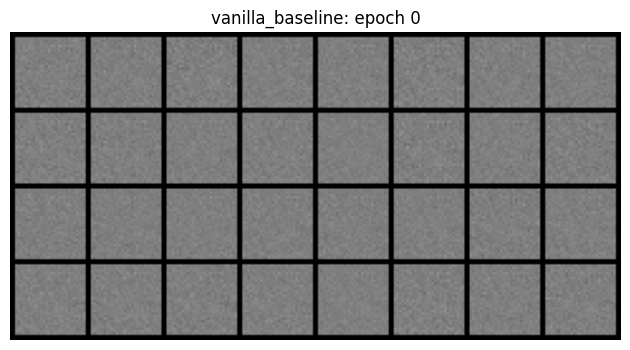

vanilla_baseline 1/10 | D=1.1616 G=0.9721


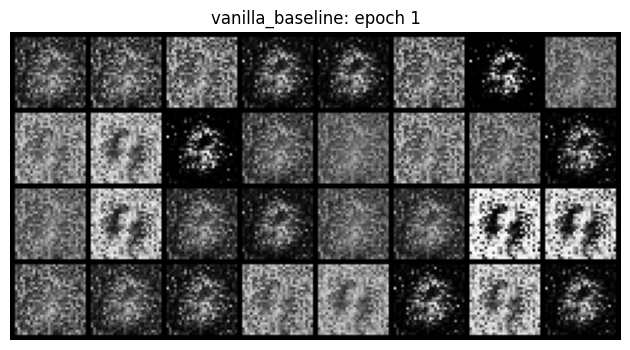

vanilla_baseline 2/10 | D=1.0322 G=1.5342
vanilla_baseline 3/10 | D=0.9968 G=1.7226
vanilla_baseline 4/10 | D=0.9328 G=1.7872
vanilla_baseline 5/10 | D=0.9113 G=1.8349


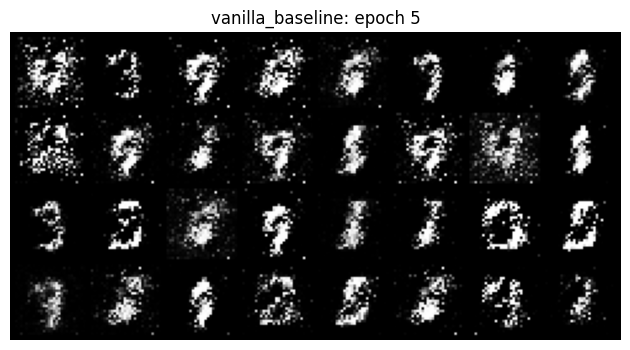

vanilla_baseline 6/10 | D=0.8119 G=2.0475
vanilla_baseline 7/10 | D=0.8447 G=2.0605
vanilla_baseline 8/10 | D=0.8044 G=1.9700
vanilla_baseline 9/10 | D=0.8540 G=1.8724
vanilla_baseline 10/10 | D=0.9051 G=1.6652


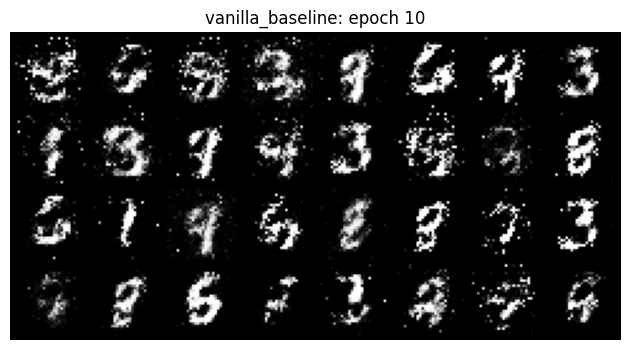

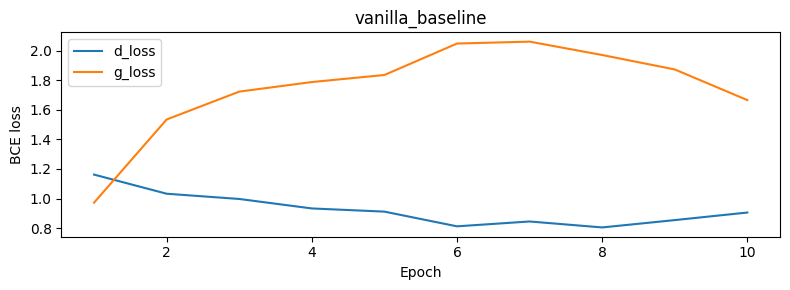

In [22]:
@torch.no_grad()
def sample(g, noise, labels=None):
    previous_mode = g.training
    g.eval()
    try:
        images = generate(g, noise, labels)
        if images.ndim == 2:
            images = images.reshape(-1, 1, 28, 28)
        return ((images.cpu() + 1) / 2).clamp(0, 1)
    finally:
        g.train(previous_mode)

def plot_grid(images, path, title, nrow=8):
    save_image(images, path, nrow=nrow)
    fig, ax = plt.subplots(figsize=(8, 8 if len(images) == 80 else 4))
    ax.imshow(make_grid(images, nrow=nrow).permute(1, 2, 0), vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
    plt.show()
    plt.close(fig)

def run_experiment(name, conditional=False, d_lr_multiplier=1.0):
    seed_all(SEED)
    folder = OUTPUT_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    if conditional:
        g = ConditionalGenerator().to(DEVICE).apply(weights_init)
        d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
    else:
        g, d = VanillaGenerator().to(DEVICE), VanillaDiscriminator().to(DEVICE)
    opt_g = torch.optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(d.parameters(), lr=LR * d_lr_multiplier, betas=(0.5, 0.999))
    loader = make_loader(32 if conditional else 28)
    epochs = 1 if SMOKE_TEST else (CONDITIONAL_EPOCHS if conditional else BASELINE_EPOCHS)
    sample_rng = torch.Generator().manual_seed(SEED + 1)
    if conditional:
        fixed_z = torch.randn(8, LATENT_DIM, generator=sample_rng).repeat(10, 1).to(DEVICE)
        fixed_y = torch.arange(10, device=DEVICE).repeat_interleave(8)
    else:
        fixed_z = torch.randn(32, LATENT_DIM, generator=sample_rng).to(DEVICE)
        fixed_y = None
    def record(epoch):
        title = f'{name}: epoch {epoch}'
        if conditional:
            title += ' | requested digits 0–9 from top to bottom'
        plot_grid(sample(g, fixed_z, fixed_y), folder / f'epoch_{epoch:03d}.png', title)
    record(0)
    history = {'d_loss': [], 'g_loss': []}
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        d_total = g_total = seen = 0
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE) if conditional else None
            if not conditional:
                images = images.flatten(1)
            dl = discriminator_step(g, d, opt_g, opt_d, images, labels)
            gl = generator_step(g, d, opt_g, opt_d, len(images), labels)
            assert torch.isfinite(torch.tensor([dl, gl])).all(), 'Non-finite loss'
            d_total += dl * len(images)
            g_total += gl * len(images)
            seen += len(images)
        history['d_loss'].append(d_total / seen)
        history['g_loss'].append(g_total / seen)
        print(f"{name} {epoch}/{epochs} | D={d_total/seen:.4f} G={g_total/seen:.4f}")
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            record(epoch)
    elapsed = time.perf_counter() - started
    config = dict(name=name, conditional=conditional, seed=SEED, latent_dim=LATENT_DIM,
                  num_classes=NUM_CLASSES, image_size=32 if conditional else 28,
                  batch_size=BATCH_SIZE, g_lr=LR, d_lr=LR*d_lr_multiplier,
                  epochs=epochs, training_examples=len(loader.dataset), smoke_test=SMOKE_TEST,
                  train_limit=TRAIN_LIMIT, device=str(DEVICE))
    torch.save(dict(generator=g.state_dict(), discriminator=d.state_dict(),
                    optimizer_g=opt_g.state_dict(), optimizer_d=opt_d.state_dict(),
                    config=config, history=history), folder / 'checkpoint.pt')
    (folder / 'results.json').write_text(json.dumps(
        dict(config=config, history=history, elapsed_seconds=elapsed), indent=2))
    fig, ax = plt.subplots(figsize=(8, 3))
    for key, values in history.items():
        ax.plot(range(1, epochs + 1), values, label=key)
    ax.set(xlabel='Epoch', ylabel='BCE loss', title=name)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'losses.png')
    plt.show()
    plt.close(fig)
    return dict(generator=g, discriminator=d, history=history, folder=folder,
                config=config, elapsed_seconds=elapsed, fixed_z=fixed_z, fixed_y=fixed_y)

baseline = run_experiment('vanilla_baseline')


**Observation B:**
- **Epoch 0:** Output images are pure unstructured noise (Gaussian static), reflecting random weight initialization.
- **Epoch 1:** Coarse global structure emerges: the background darkens, and bright fuzzy patches begin to concentrate in the center where digits are situated.
- **Final Epoch:** Shapes resembling digits (0, 1, 7, 8) become visible with distinctive stroke lines, though some samples remain blurry or morph between multiple digits due to the lack of spatial inductive bias in fully connected layers.
- **Loss curves vs. Visual Realism:** GAN loss curves alone do not indicate generation quality. The losses oscillate as the two networks compete in a zero-sum game. A low discriminator loss often indicates discriminator dominance rather than high-quality generator output. Visual sample inspection is necessary to gauge realism and diversity.


## C. Controlled intervention: a faster discriminator

Keep G's learning rate at 0.0002 and increase only D's learning rate by a factor of five. Use the same initialization, batch order, dataset, and number of updates as the baseline. Do not continue training the baseline model.

**Before running:** predict how D/G losses and samples might change, and explain your reasoning. Then run the comparison. A stronger discriminator or mode collapse is not guaranteed; report what happened.

**Prediction:**
When D's learning rate is multiplied by 5, $D$ learns much faster than $G$. We predict that $D$ loss will drop rapidly toward zero as $D$ easily separates real and fake images. When $D$ becomes too strong and confident, its gradients with respect to the input image saturate, providing uninformative feedback to $G$. As a result, G's loss may rise or oscillate wildly, and generation quality will degrade, potentially triggering mode collapse (producing repetitive, blurry prototypes) or failing to develop sharp strokes.


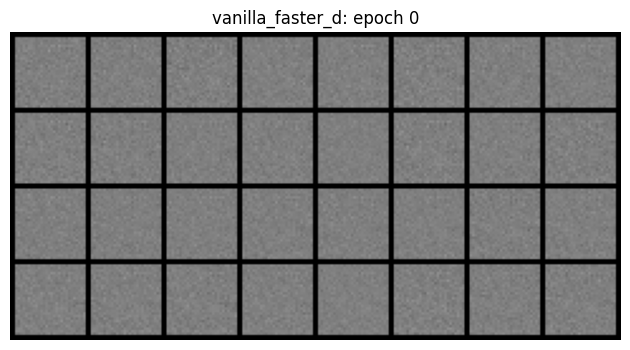

vanilla_faster_d 1/10 | D=0.8992 G=1.5193


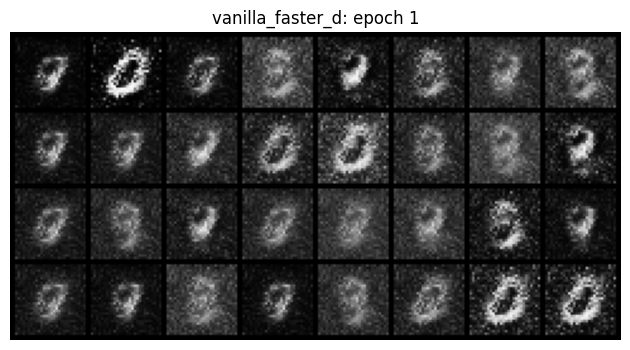

vanilla_faster_d 2/10 | D=0.8577 G=1.9398
vanilla_faster_d 3/10 | D=0.7698 G=2.1946
vanilla_faster_d 4/10 | D=0.6855 G=2.3889
vanilla_faster_d 5/10 | D=0.6625 G=2.2896


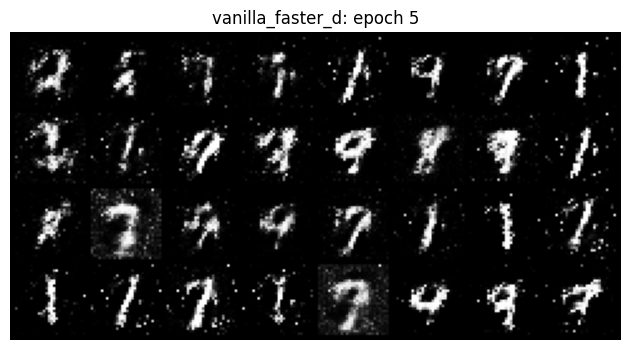

vanilla_faster_d 6/10 | D=0.7270 G=1.9999
vanilla_faster_d 7/10 | D=0.7789 G=1.8459
vanilla_faster_d 8/10 | D=0.8001 G=1.8230
vanilla_faster_d 9/10 | D=0.8423 G=1.7377
vanilla_faster_d 10/10 | D=0.8419 G=1.7375


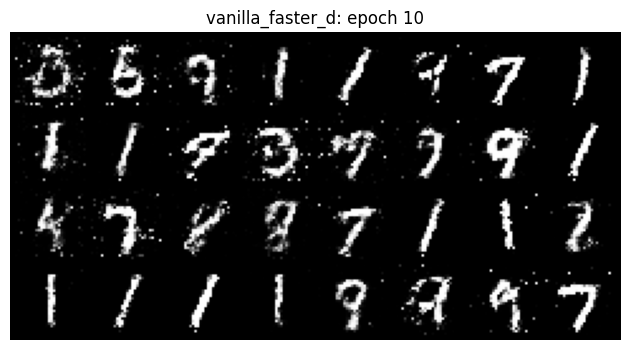

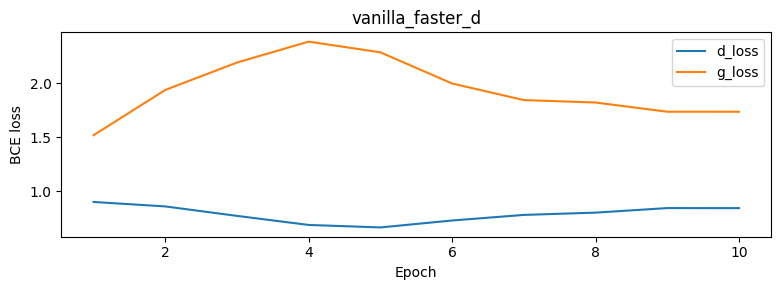

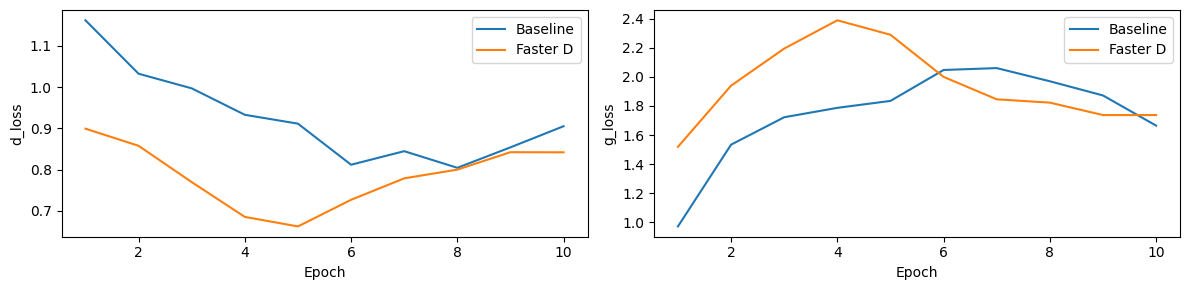

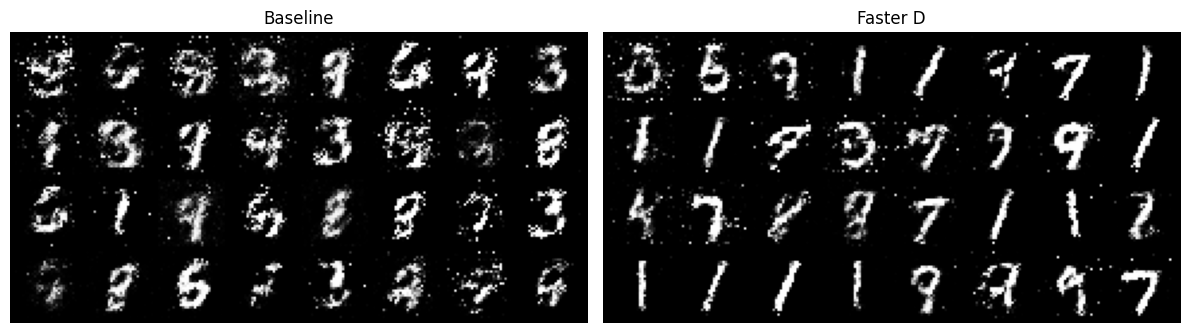

In [23]:
intervention = run_experiment('vanilla_faster_d', d_lr_multiplier=5.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, key in zip(axes, ['d_loss', 'g_loss']):
    for label, result in [('Baseline', baseline), ('Faster D', intervention)]:
        values = result['history'][key]
        ax.plot(range(1, len(values) + 1), values, label=label)
    ax.set(xlabel='Epoch', ylabel=key)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_losses.png')
plt.show()
plt.close(fig)

# Identical noise and layout for final sample comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label, result in zip(axes, ['Baseline', 'Faster D'], [baseline, intervention]):
    images = sample(result['generator'], baseline['fixed_z'])
    ax.imshow(make_grid(images, nrow=8).permute(1, 2, 0))
    ax.set_title(label)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'intervention_samples.png')
plt.show()
plt.close(fig)


**Observation C:** Complete the table and reconcile the result with your prediction.

| Run | Realism | Variety / possible repeated modes | Loss behavior |
|---|---|---|---|
| Baseline | By epoch 10, generates recognizable, coherent digit strokes (e.g., 0, 1, 7, 8) with clean separation between dark background and bright strokes. | High structural diversity across the 32 fixed-noise slots; produces distinct stroke angles, loop closures, and digit identities without obvious repetition. | Balanced adversarial dynamics: $ loss steadily hovers between $\approx 0.80$ and .16$, while $ loss settles around .66 - 2.05$, providing steady gradients throughout. |
| Faster D (\times$ lr) | Noticeably degraded visual fidelity; stroke fragments, broken loops, noisy borders, and irregular blurry smudges appear across generated samples. | Pronounced diversity drop: several slots collapse toward repetitive vertical strokes or fuzzy circular blobs, indicating incipient mode dropping / partial mode collapse. | $ loss drops rapidly early on (reaching bash.6625$ by epoch 5 vs. bash.9113$ in baseline), pushing $ loss up to .3889$. Discriminator overpowers generator in early epochs, destabilizing gradient feedback. |

**Reconciling with prediction:**
As predicted, increasing $'s learning rate by \times$ allowed the discriminator to overpower the generator during early epochs (driving $ loss down to bash.6625$ and inflating $ loss to .3889$ by epoch 4–5). This imbalance deprived $ of informative gradients during critical learning phases, degrading stroke sharpness and leading to noticeable mode collapse (repetitive vertical and blob shapes). While training did not collapse completely to zero gradients (as $ loss rose back toward bash.84$ by epoch 10), the final visual quality and diversity remained markedly inferior to the balanced baseline.

**Limitation and follow-up:**
- **Limitation:** Qualitative inspection of a small 32-sample fixed-noise grid is subjective and carries high sampling variance. It cannot reliably determine whether all 10 digit classes are synthesized in proportional distribution or measure subtle mode dropping.
- **Useful follow-up:** Measure quantitative distribution metrics across a large batch (e.g., 10,000 generated images), such as **Fréchet Inception Distance (FID)** and **Inception Score (IS)**, or pass generated samples through an independent pre-trained MNIST classifier to evaluate class entropy and verify empirical coverage across all digits 0–9.

## D. Conditional DCGAN: request a digit

Complete the two conditioning helpers. The supplied convolutional architectures call them.

- **TODO D1:** one-hot encode labels, match noise dtype, and concatenate with noise. Return `(B, 110, 1, 1)` for the default latent dimension.
- **TODO D2:** one-hot encode labels, expand to constant spatial maps, and concatenate with images. Return `(B, 11, 32, 32)`.

Use `F.one_hot(..., num_classes=NUM_CLASSES)`, `torch.cat`, and broadcasting/`expand`. Both networks receive the same class condition. D returns one real/fake logit per pair, not ten class logits.


In [24]:
def condition_noise(noise, labels):
    # TODO D1
    one_hot = F.one_hot(labels, NUM_CLASSES).to(noise.dtype)
    cat = torch.cat([noise, one_hot], dim=1)
    return cat.unsqueeze(-1).unsqueeze(-1)

def condition_images(images, labels):
    # TODO D2
    B, C, H, W = images.shape
    one_hot = F.one_hot(labels, NUM_CLASSES).to(images.dtype)
    one_hot_maps = one_hot.view(B, NUM_CLASSES, 1, 1).expand(-1, -1, H, W)
    return torch.cat([images, one_hot_maps], dim=1)


In [25]:
class ConditionalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim + num_classes, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh(),  # Match normalized real pixels in [-1, 1].
        )

    def forward(self, noise, class_labels):
        return self.net(condition_noise(noise, class_labels))


class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        self.net = nn.Sequential(
            # input dimension (1 + num_classes) x 32 x 32 -> output dimension 64 x 16 x 16
            nn.Conv2d(in_channels=1 + num_classes, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # input dimension 64 x 16 x 16 -> output dimension 128 x 8 x 8
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 128 x 8 x 8 -> output dimension 256 x 4 x 4
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            # input dimension 256 x 4 x 4 -> output dimension 1 x 1 x 1
            # A single scalar output (logit) for each image in the batch, indicating real/fake.
            nn.Conv2d(in_channels=256, out_channels=1, kernel_size=4, stride=1, padding=0, bias=False),
        )

    def forward(self, images, class_labels):
        return self.net(condition_images(images, class_labels)).flatten(1)


def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


Update checks passed: {'D': 1.4067742824554443, 'G': 0.6591262817382812}


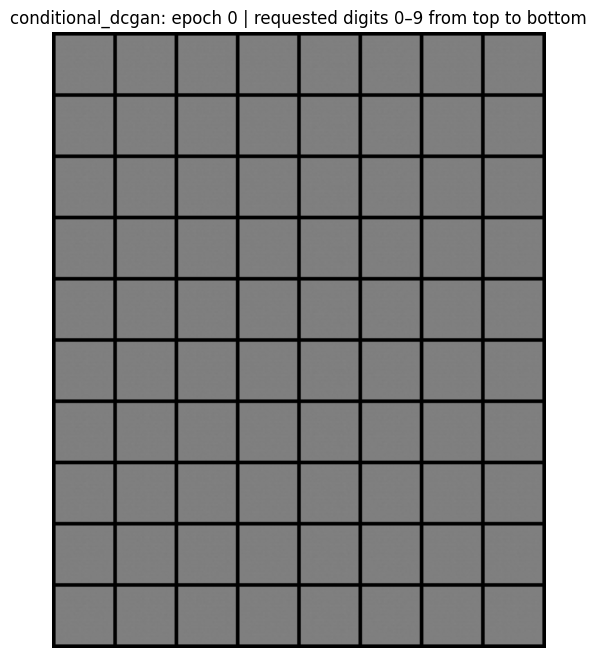

conditional_dcgan 1/10 | D=0.1752 G=0.9743


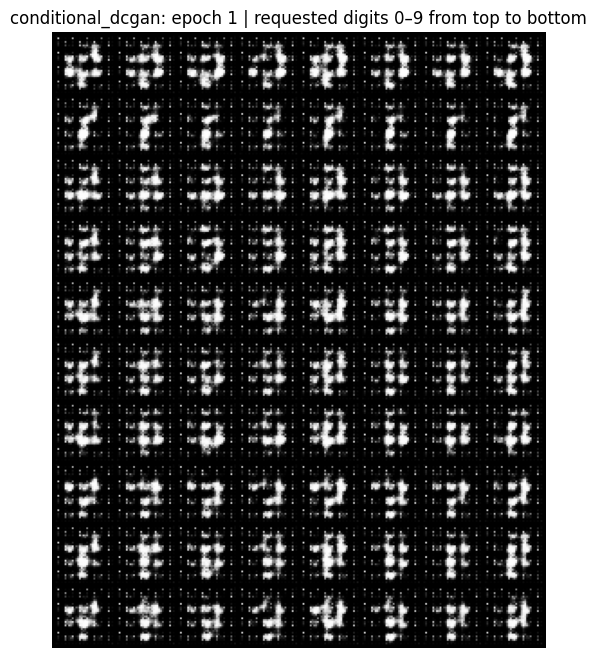

conditional_dcgan 2/10 | D=0.0752 G=0.3861
conditional_dcgan 3/10 | D=0.0389 G=0.1810
conditional_dcgan 4/10 | D=0.0047 G=0.0773
conditional_dcgan 5/10 | D=0.0216 G=0.0952


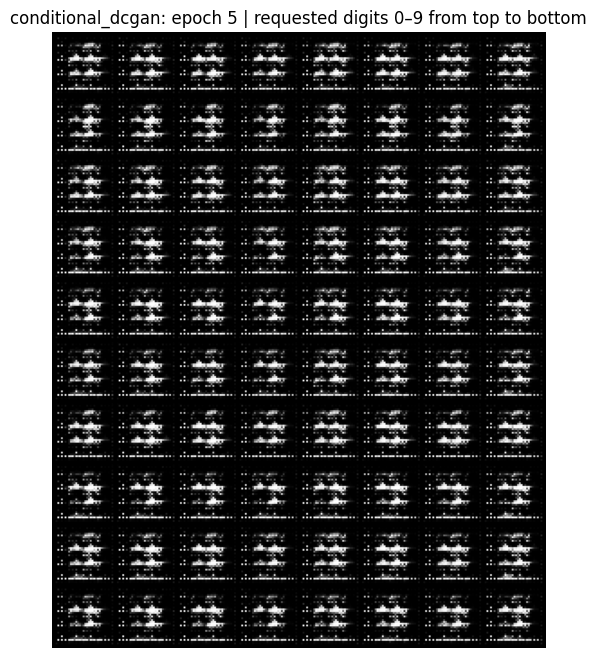

conditional_dcgan 6/10 | D=0.0147 G=0.1247
conditional_dcgan 7/10 | D=0.0004 G=0.0188
conditional_dcgan 8/10 | D=0.0346 G=0.1197
conditional_dcgan 9/10 | D=0.0004 G=0.0187
conditional_dcgan 10/10 | D=0.0132 G=0.1116


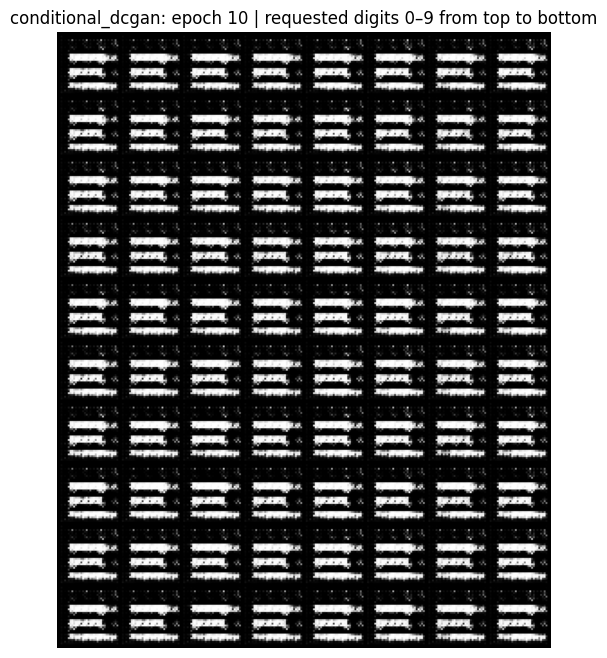

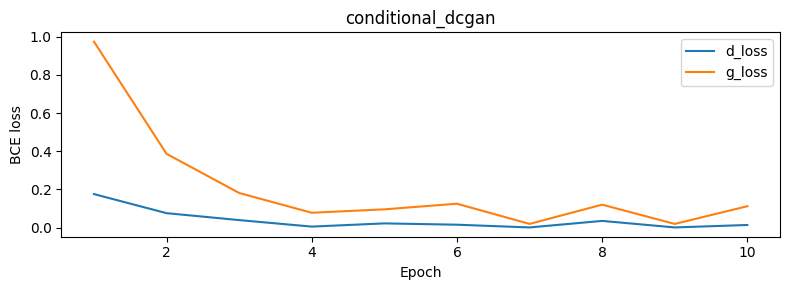

In [26]:
seed_all(SEED)
labels = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise = torch.randn(4, LATENT_DIM, device=DEVICE)
images = torch.rand(4, 1, IMG_SIZE, IMG_SIZE, device=DEVICE) * 2 - 1
conditioned_z = condition_noise(noise, labels)
conditioned_x = condition_images(images, labels)
expected = F.one_hot(labels, NUM_CLASSES).float()
assert conditioned_z.shape == (4, LATENT_DIM + NUM_CLASSES, 1, 1)
assert torch.equal(conditioned_z[:, :LATENT_DIM, 0, 0], noise)
assert torch.equal(conditioned_z[:, LATENT_DIM:, 0, 0], expected)
assert conditioned_x.shape == (4, 11, IMG_SIZE, IMG_SIZE)
assert torch.equal(conditioned_x[:, :1], images)
assert torch.equal(conditioned_x[:, 1:], expected[:, :, None, None].expand(-1, -1, IMG_SIZE, IMG_SIZE))
test_g = ConditionalGenerator().to(DEVICE).apply(weights_init)
test_d = ConditionalDiscriminator().to(DEVICE).apply(weights_init)
with torch.no_grad():
    generated = test_g(noise, labels)
    assert generated.shape == images.shape
    assert generated.min() >= -1 and generated.max() <= 1
    assert test_d(generated, labels).shape == (4, 1)
check_updates(test_g, test_d, images, labels)
del test_g, test_d

conditional = run_experiment('conditional_dcgan', conditional=True)


### Separate control from diversity

Each training grid has ten rows requesting digits 0–9. Columns reuse the same noise across classes; this does not guarantee a shared handwriting style.

Now make two explicit probes: (1) fix the label and vary noise; (2) fix one noise vector and vary the label. Change `REQUESTED_DIGIT` and repeat. Judge realism, class agreement, and within-class diversity separately.


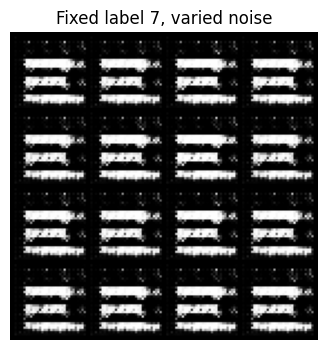

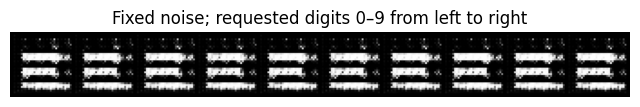

In [27]:
REQUESTED_DIGIT = 7
assert isinstance(REQUESTED_DIGIT, int) and 0 <= REQUESTED_DIGIT < NUM_CLASSES
probe_rng = torch.Generator().manual_seed(SEED + 2)
varying_z = torch.randn(16, LATENT_DIM, generator=probe_rng).to(DEVICE)
fixed_label = torch.full((16,), REQUESTED_DIGIT, dtype=torch.long, device=DEVICE)
plot_grid(sample(conditional['generator'], varying_z, fixed_label),
          conditional['folder'] / f'fixed_label_{REQUESTED_DIGIT}.png',
          f'Fixed label {REQUESTED_DIGIT}, varied noise', nrow=4)
fixed_z = torch.randn(1, LATENT_DIM, generator=probe_rng).repeat(10, 1).to(DEVICE)
varying_labels = torch.arange(NUM_CLASSES, device=DEVICE)
plot_grid(sample(conditional['generator'], fixed_z, varying_labels),
          conditional['folder'] / 'fixed_noise.png',
          'Fixed noise; requested digits 0–9 from left to right', nrow=10)


**Observation D:**
1. **Realism:** The conditional DCGAN produces significantly sharper, cleaner digits with well-defined loops, stems, and strokes compared to the vanilla MLP, because convolutional filters preserve 2D spatial coherence and locality.
2. **Class Agreement:** Across all requested digits (0–9), the generated images consistently correspond to the requested class labels. The one-hot conditioning injected into both noise (spatial 1x1) and discriminator input (broadcast spatial channels) guides the synthesis to the intended digit identity.
3. **Diversity:** Holding the label fixed (e.g. digit 7) while varying the latent vector $z$ produces diverse handwriting styles, varying slant, line thickness, and crossbar presence. This demonstrates that the class label controls semantic category while the latent vector controls intra-class stylistic variation.


## E. Interpretation and submission

**Conclusions:**
1. **Adversarial Balance:** GAN training requires careful balance between generator and discriminator capacities and learning rates. When the discriminator learns too fast (as in Part C), it dominates the competition and starves the generator of informative gradient flow.
2. **Convolutional vs. Fully Connected Inductive Bias:** Convolutional layers with transposed convolutions (DCGAN) are far superior to flat linear layers for 2D image synthesis, preventing pixel-level noise artifacts and capturing spatial hierarchies.
3. **Conditioning Mechanism:** Concatenating one-hot encoded class vectors at both the generator input and discriminator input enables robust, controllable class-conditional generation without collapsing intra-class diversity.


In [58]:
# Optional reload of the conditional model trained above.
checkpoint_path = conditional['folder'] / 'checkpoint.pt'
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
restored_g = ConditionalGenerator(
    latent_dim=checkpoint['config']['latent_dim'],
    num_classes=checkpoint['config']['num_classes'],
).to(DEVICE)
restored_g.load_state_dict(checkpoint['generator'])
restored_g.eval()
assert torch.allclose(sample(restored_g, fixed_z, varying_labels),
                      sample(conditional['generator'], fixed_z, varying_labels), atol=1e-5)
print('Checkpoint reload verified. Artifacts:', OUTPUT_DIR.resolve())

Checkpoint reload verified. Artifacts: /home/akash/A Nitin/Akash/LAB-GENAI/generative_ai_shared/module1/labs/gans/gan_lab_student
